Dataset Set up

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
data = '/content/drive/MyDrive/StudentGradesDataset.csv'
df = pd.read_csv(data)
from IPython.display import display

Mounted at /content/drive


Data Inspection (going through the data to make sure everything is right)

In [ ]:
print("Rows, Columns:", df.shape)
#column names
print("....Column names...", df.columns)
#Data info
print("...Data info... ")
print(df.info())
#First 5 dataset
print("...First 5 dataset...", df.head(5))
#Missing values check
print("...Missing Values...", df.isnull().sum())


Rows, Columns: (16823, 20)
....Column names... Index(['Serial No', 'School Name', 'Class', 'Years', 'Religion', 'Kurdish',
       'Arabic', 'English', 'Math', 'Physic', 'Chemistry', 'Biology',
       'Computer', 'History', 'Geography', 'Economics', 'Sociology',
       'philosophy', 'Science', 'Social'],
      dtype='object')
...Data info... 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16823 entries, 0 to 16822
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Serial No    16823 non-null  int64  
 1   School Name  16823 non-null  object 
 2   Class        16823 non-null  int64  
 3   Years        16823 non-null  object 
 4   Religion     15893 non-null  float64
 5   Kurdish      16695 non-null  float64
 6   Arabic       16694 non-null  float64
 7   English      16693 non-null  float64
 8   Math         16693 non-null  float64
 9   Physic       4020 non-null   float64
 10  Chemistry    4020 non-null   float64
 

In [ ]:
core_subjects = ["Math", "English", "Computer", "Kurdish", "Arabic", "Religion"]
subject_means = {}
for subject in core_subjects:
  subject_means[subject] = df[subject].mean()
print("Subject Averages:", subject_means)

print(df.columns)
yearly_avg = df.groupby("Years")[core_subjects].mean()
print(yearly_avg)

Subject Averages: {'Math': np.float64(56.439076259509974), 'English': np.float64(58.73446953812976), 'Computer': np.float64(68.20254144652942), 'Kurdish': np.float64(62.84513327343516), 'Arabic': np.float64(59.05031747933389), 'Religion': np.float64(73.73919335556535)}
Index(['Serial No', 'School Name', 'Class', 'Years', 'Religion', 'Kurdish',
       'Arabic', 'English', 'Math', 'Physic', 'Chemistry', 'Biology',
       'Computer', 'History', 'Geography', 'Economics', 'Sociology',
       'philosophy', 'Science', 'Social'],
      dtype='object')
                Math    English   Computer    Kurdish     Arabic   Religion
Years                                                                      
2019-2018  38.833333  52.000000  63.666667  56.833333  47.833333  77.500000
2020-2019  58.364803  59.958210  70.459244  63.753618  59.275000  73.198684
2021-2020  52.571429  57.314161  95.105263  63.002501  56.967959  72.371215
2022-2021  56.482186  57.985188  66.729202  61.920752  58.315753  74.0

Question 1: Which core subjects have the highest and lowest perfomance?

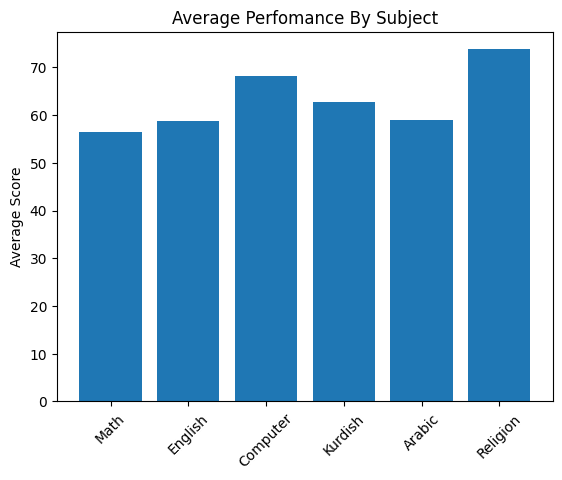

In [ ]:
plt.bar(subject_means.keys(), subject_means.values())
plt.title("Average Perfomance By Subject")
plt.ylabel("Average Score")
plt.xticks(rotation = 45)
plt.show()


Question 2: How does perfomance change across academic years?

Years
2019-2018    56.111111
2020-2019    64.168260
2021-2020    66.222088
2022-2021    62.574655
2023-2022    63.937646
dtype: float64


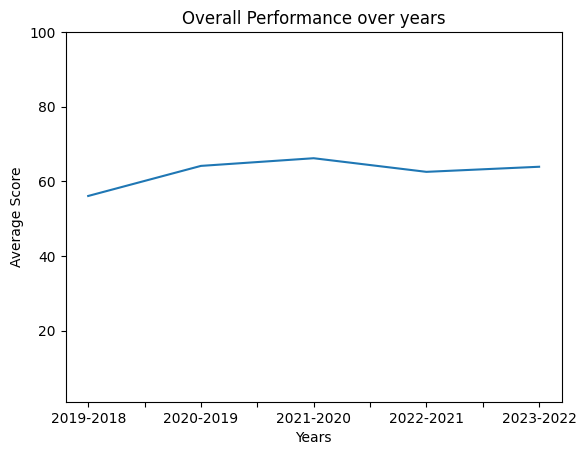

In [ ]:
overall_yearly_avg = yearly_avg.mean(axis=1)
print(overall_yearly_avg)

overall_yearly_avg.plot(kind="line")
plt.title("Overall Performance over years")
plt.ylabel("Average Score")
plt.ylim(1,100)
plt.show()

3. Do students in different academic tracks peform differently?

In [ ]:
NaturalScience_track = ["Physic", "Chemistry", "Biology"]
humanieties_track = ["History", "philosophy"]
SocialScience_track = ["Geography", "Sociology","Economics"]

NaturalScience_data= df[NaturalScience_track].dropna()
humanities_data = df[humanieties_track].dropna()
SocialScience_data= df[SocialScience_track].dropna()

print("Natural Science Track Averages: ", NaturalScience_data.mean().mean())
print("Humanities_track: ", humanities_data.mean().mean())
print("Social Science Track Averages:", SocialScience_data.mean().mean())


Natural Science Track Averages:  55.05746268656716
Humanities_track:  54.589015151515156
Social Science Track Averages: 51.35253542132737


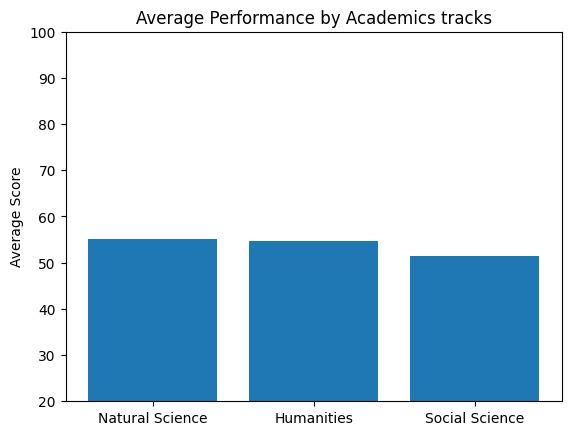

In [ ]:
plt.bar(["Natural Science", "Humanities", "Social Science"],[NaturalScience_data.mean().mean(), humanities_data.mean().mean(), SocialScience_data.mean().mean()])
plt.title("Average Performance by Academics tracks")
plt.ylabel("Average Score")
plt.ylim(20,100)
plt.show()

In [ ]:
pf= pd.read_csv(data,encoding='utf-8')
pf=pd.read_csv(data,encoding='utf-8-sig')
pf= pd.read_csv(data,encoding='cp1256' )
print(pf["School Name"].nunique())
print(pf.columns)

24
Index(['Serial No', 'School Name', 'Class', 'Years', 'Religion', 'Kurdish',
       'Arabic', 'English', 'Math', 'Physic', 'Chemistry', 'Biology',
       'Computer', 'History', 'Geography', 'Economics', 'Sociology',
       'philosophy', 'Science', 'Social'],
      dtype='object')


Do Schools have different perfomance levels?

In [ ]:
school_avg = df.groupby("School Name")[core_subjects].mean()
school_overall = school_avg.mean(axis=1).sort_values(ascending=False)
print(school_overall.head(10))

School Name
?????? ???????? ??????? ????                     88.355983
?????? ???????? ?????? ??????? ?????             83.397154
?????????? ????? ????? ???????                   75.258155
?????????? ???????                               67.514211
?????????? ???                                   67.082955
?????????? ????                                  66.362099
??????? ???????? ?????????? ???????? ???????     65.365795
?????????? ??????? ????                          65.238520
?????????? ??? ????                              63.943970
?????????? ?????? ????                           63.816856
dtype: float64


What relationships exist between subjects

              Math   English  Computer   Kurdish    Arabic  Religion
Math      1.000000  0.769515  0.719236  0.796835  0.756079  0.680977
English   0.769515  1.000000  0.765869  0.789452  0.788664  0.695714
Computer  0.719236  0.765869  1.000000  0.785164  0.776099  0.753213
Kurdish   0.796835  0.789452  0.785164  1.000000  0.809455  0.759267
Arabic    0.756079  0.788664  0.776099  0.809455  1.000000  0.797804
Religion  0.680977  0.695714  0.753213  0.759267  0.797804  1.000000


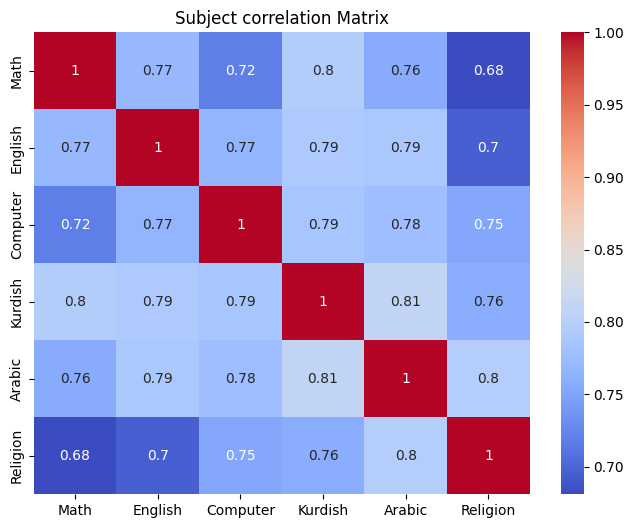

In [ ]:
corr = df[core_subjects].corr()
print(corr)

import seaborn as sns
plt.figure(figsize = (8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Subject correlation Matrix")
plt.show()

In [ ]:
print("rows and columns", df.shape)
print("dataset information", df.info())
print("missing values", df.isnull().sum())

rows and columns (16823, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16823 entries, 0 to 16822
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Serial No    16823 non-null  int64  
 1   School Name  16823 non-null  object 
 2   Class        16823 non-null  int64  
 3   Years        16823 non-null  object 
 4   Religion     15893 non-null  float64
 5   Kurdish      16695 non-null  float64
 6   Arabic       16694 non-null  float64
 7   English      16693 non-null  float64
 8   Math         16693 non-null  float64
 9   Physic       4020 non-null   float64
 10  Chemistry    4020 non-null   float64
 11  Biology      4020 non-null   float64
 12  Computer     10978 non-null  float64
 13  History      1290 non-null   float64
 14  Geography    1290 non-null   float64
 15  Economics    1290 non-null   float64
 16  Sociology    894 non-null    float64
 17  philosophy   396 non-null    float64
 18  Science      1138

In [ ]:
df.isnull().sum()

,0
Serial No,0
School Name,0
Class,0
Years,0
Religion,930
Kurdish,128
Arabic,129
English,130
Math,130
Physic,12803


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("subashmaster0411/social-media-engagement-dataset")

print("Path to dataset files:", path)